# Cyclistic Bike-Share Case Study, Part 2: Analysis & Recommendations
**Author:** Makiko Tsuda · **Last updated:** October 2026 · **Data:** Divvy trips, January–December 2025

## Introduction
This is the capstone case study from the Google Data Analytics Professional Certificate. Cyclistic is a fictional bike-share company; the trip data is real, published by Divvy, Chicago’s bike-share system. I analyzed the full 2025 dataset (5.55 million rides; 5.4 million after cleaning) in Python, added daily weather data and OpenStreetMap points of interest, and built an interactive station map in Tableau to test where casual riders concentrate.

**Business question:** How do annual members and casual riders use Cyclistic bikes differently?

### About this notebook

This notebook answers that question and discusses the following: 
- the business task, 
- the summary of analysis, 
- supporting visualizations,
- key findings, and 
- the top three recommendations. 

The data sources and cleaning steps (deliverables 2 and 3) are documented in `01_prepare_and_clean.ipynb`.

## Business task

Cyclistic's finance team has found that annual members are more profitable than casual riders, and the director of marketing wants to grow membership by converting existing casual riders. **This analysis identifies how casual riders and members use the bikes differently in 2025**, so that the marketing team can design a conversion campaign around when, how long and where casual riders actually ride.

**Stakeholders:** Lily Moreno (Director of Marketing), the marketing analytics team, and the Cyclistic executive team, who will approve or reject the campaign.

## Key findings

Based on 5.4 million rides in 2025, after cleaning:

1. **Casual riders use the bikes far more than ride counts suggest.** They take 35.5% of rides but account for 47.3% of total riding time, because their average ride is 19.9 minutes versus 12.2 for members.
2. **Casual riding is a warm-weather activity.** Casual rides grow 14 times from January to August, compared with 4 times for members. From June to August, casual riders account for more riding time than members (54–56%).
3. **Members commute; casual riders ride for leisure.** Members ride most from Tuesday to Thursday, with weekday peaks at 8am and 5pm. Casual riders peak on Saturday, when they take 47% of all rides, and on weekdays their riding builds through the afternoon.
4. **Typical rides are similar, but casual riders have a long tail.** Median rides are 8.7 minutes (members) and 11.9 minutes (casual), but 15.6% of casual rides last over 30 minutes, compared with 5.4% of member rides.
5. **Casual riders gather at the lakefront and major attractions.** Their busiest stations are Navy Pier, Millennium Park, Shedd Aquarium and the lakefront trail, where about 70–80% of riders are casual. Members' busiest stations are in the West Loop and River North, near the commuter rail stations.

**Top three recommendations** (details in section 7): 
1. a seasonal summer membership, 
2. membership benefits built around longer leisure rides with weekend-focused messaging, and 
3. on-site promotions with partner discounts at the lakefront and attraction stations.

## Setup

In [1]:
# Import packages
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# display attributes
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

data_dir = Path("..")
output_folder = "processed"

# Cleaned and processed in the 01_prepare_and_clean.ipynb
rides = pd.read_parquet(data_dir / output_folder / "rides_2025_clean.parquet")
temps = pd.read_csv(data_dir / output_folder / "chicago_monthly_temp_summary.csv", index_col="month")
places = pd.read_csv(data_dir / output_folder / "places.csv")

# One color per rider type, used in every chart
COLORS = {"member": "#4C72B0", "casual": "#DD8452"}
GROUPS = ["member", "casual"]
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def tidy(ax):
    """Shared chart style: no top/right border, light horizontal grid."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

print(f"{len(rides):,} rides loaded")

5,399,955 rides loaded


## 1. The big picture: casual riders take a third of rides but nearly half of riding time

Counting rides makes casual riders look like a minority. Measuring how long the bikes are actually in use tells a different story.

In [2]:
usage = rides.groupby("member_casual", observed=True).agg(
    rides=("duration_min", "size"),
    total_hours=("duration_min", lambda s: s.sum() / 60),
    avg_min=("duration_min", "mean"),
    median_min=("duration_min", "median"),
).reindex(GROUPS)

usage["share_of_rides_pct"] = usage["rides"] / usage["rides"].sum() * 100
usage["share_of_riding_time_pct"] = usage["total_hours"] / usage["total_hours"].sum() * 100
usage.round(1)

,rides,total_hours,avg_min,median_min,share_of_rides_pct,share_of_riding_time_pct
member_casual,,,,,,
member,3484186,707275.5,12.2,8.7,64.5,52.7
casual,1915769,635560.2,19.9,11.9,35.5,47.3


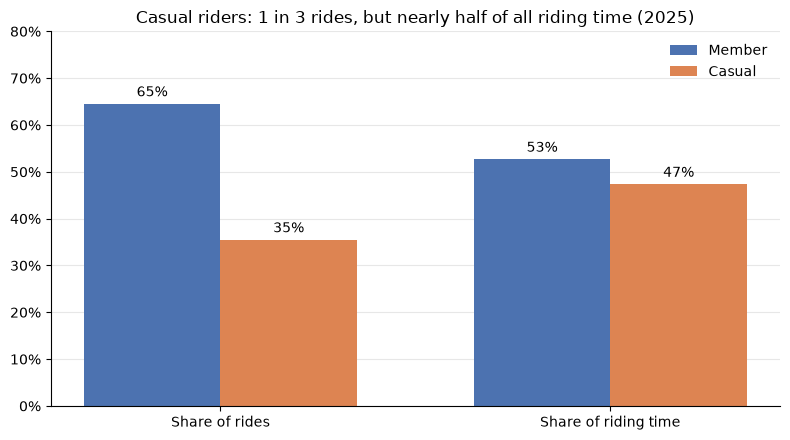

In [3]:
# Compare each group's share of rides and share of riding time.
fig, ax = plt.subplots(figsize=(8, 4.5))
measures = ["share_of_rides_pct", "share_of_riding_time_pct"]
x = np.arange(len(measures))
width = 0.35

for i, g in enumerate(GROUPS):
    values = usage.loc[g, measures]
    bars = ax.bar(x + (i - 0.5) * width, values, width, color=COLORS[g], label=g.capitalize())
    ax.bar_label(bars, fmt="%.0f%%", padding=3)

# set up axis
ax.set_xticks(x, ["Share of rides", "Share of riding time"])
ax.set_ylim(0, 80)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title("Casual riders: 1 in 3 rides, but nearly half of all riding time (2025)")
ax.legend(frameon=False)
tidy(ax)
plt.tight_layout()
plt.show()

## 2. When: casual riding is highly seasonal

Members ride all year. Casual riding rises and falls with the weather, and in the warmest months casual riders use the bikes more than members do (in number of hours).

In [4]:
monthly_rides = rides.groupby(["month", "member_casual"], observed=True).size().unstack()[GROUPS]
monthly_hours = rides.groupby(["month", "member_casual"], observed=True)["duration_min"].sum().unstack()[GROUPS] / 60

# Put number of rides and hours of rides by month with the average temperature in one table to compare.
monthly = pd.DataFrame({
    "member_rides": monthly_rides["member"],
    "casual_rides": monthly_rides["casual"],
    "casual_share_of_rides_pct": monthly_rides["casual"] / monthly_rides.sum(axis=1) * 100,
    "casual_share_of_time_pct": monthly_hours["casual"] / monthly_hours.sum(axis=1) * 100,
    "avg_temp_2025_f": temps["temp_2025_f"],
})
monthly.round(1)

,member_rides,casual_rides,casual_share_of_rides_pct,casual_share_of_time_pct,avg_temp_2025_f
month,,,,,
1,112331,23405,17.2,20.0,22.3
2,122097,27003,18.1,21.6,26.2
3,208458,82864,28.4,39.0,42.9
4,257921,105260,29.0,40.3,49.5
5,313996,175655,35.9,49.5,55.5
6,379523,278702,42.3,55.6,71.8
7,430394,308446,41.7,53.9,76.2
8,443130,323533,42.2,54.8,72.7
9,440954,254727,36.6,47.2,67.5


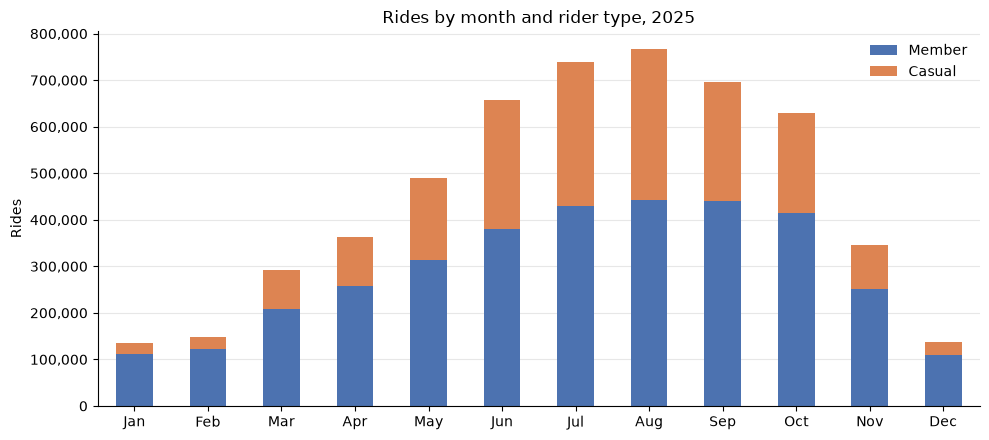

In [5]:
# First, visualize monthly rides by number of rides and rider group
ax = monthly_rides.plot(kind="bar", stacked=True, figsize=(10, 4.5), rot=0,
                       color=[COLORS[g] for g in GROUPS])
ax.set_xticklabels(month_labels)
ax.set_xlabel("")
ax.set_ylabel("Rides")
ax.set_title("Rides by month and rider type, 2025")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(["Member", "Casual"], frameon=False)
tidy(ax)
plt.tight_layout()
plt.show()

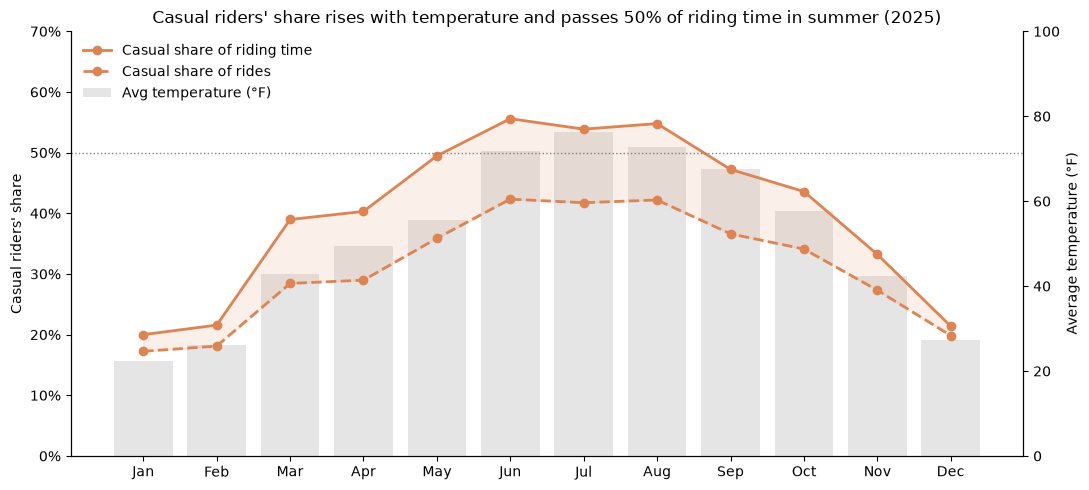

In [6]:
# Second, casual share of rides and of riding time (lines) with average temperature (bars), by month.
fig, ax1 = plt.subplots(figsize=(11, 5))

# Right axis (drawn first, in the background): temperature
# The temperature data extracted and downloaded from Open-Meteo, https://open-meteo.com/.
# The data had been processed in 01_prepare_and_clean.ipynb
ax2 = ax1.twinx()
ax2.bar(month_labels, monthly["avg_temp_2025_f"], color="gray", alpha=0.2, label="Avg temperature (°F)")
ax2.set_ylim(0, 100)
ax2.set_ylabel("Average temperature (°F)")

# Left axis: casual share of rides and of riding time
ax1.plot(month_labels, monthly["casual_share_of_time_pct"], marker="o", linewidth=2,
         color=COLORS["casual"], label="Casual share of riding time")
ax1.plot(month_labels, monthly["casual_share_of_rides_pct"], marker="o", linewidth=2, linestyle="--",
         color=COLORS["casual"], label="Casual share of rides")
ax1.fill_between(month_labels, monthly["casual_share_of_rides_pct"], monthly["casual_share_of_time_pct"],
                 color=COLORS["casual"], alpha=0.12)
ax1.axhline(50, color="gray", linestyle=":", linewidth=1)
ax1.set_ylim(0, 70)
ax1.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax1.set_ylabel("Casual riders' share")

ax1.set_zorder(ax2.get_zorder() + 1)   # lines on top of the bars
ax1.patch.set_visible(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=False)
ax1.set_title("Casual riders' share rises with temperature and passes 50% of riding time in summer (2025)")
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
# How closely does casual riding follow temperature? (12 months, so a rough guide only)
r_casual = monthly["casual_rides"].corr(monthly["avg_temp_2025_f"])
r_member = monthly["member_rides"].corr(monthly["avg_temp_2025_f"])
print(f"Correlation of monthly rides with temperature: casual {r_casual:.2f}, member {r_member:.2f}")
print(f"August vs. January rides: casual x{monthly.loc[8, 'casual_rides'] / monthly.loc[1, 'casual_rides']:.0f}, "
      f"member x{monthly.loc[8, 'member_rides'] / monthly.loc[1, 'member_rides']:.0f}")

# Was 2025 a typical year? Compare with the 2020-2025 monthly average.
temps[["temp_2025_f", "temp_normal_f", "diff_from_normal_f"]].T

Correlation of monthly rides with temperature: casual 0.98, member 0.96
August vs. January rides: casual x14, member x4


month,1,2,3,4,5,6,7,8,9,10,11,12
temp_2025_f,22.3,26.2,42.9,49.5,55.5,71.8,76.2,72.7,67.5,57.6,42.3,27.4
temp_normal_f,26.4,28.2,40.0,48.2,58.2,70.8,74.0,73.2,67.4,55.6,43.0,32.7
diff_from_normal_f,-4.1,-2.0,2.9,1.3,-2.7,1.0,2.2,-0.5,0.1,2.0,-0.7,-5.3


## 3. When: members commute on weekdays; casual riders ride on weekends and afternoons

Members take about twice as many rides as casual riders, so the charts below show each group's rides as a **percentage of that group's own total**. That way the two groups' patterns can be compared directly.

In [8]:
weekly = (pd.crosstab(rides["weekday"], rides["member_casual"], normalize="columns")
          .reindex(day_order)[GROUPS] * 100)

weekly_counts = pd.crosstab(rides["weekday"], rides["member_casual"]).reindex(day_order)[GROUPS]
weekly["casual_share_of_day_pct"] = weekly_counts["casual"] / weekly_counts.sum(axis=1) * 100
weekly.round(1)

member_casual,member,casual,casual_share_of_day_pct
weekday,,,
Monday,14.2,11.4,30.8
Tuesday,15.9,11.3,28.2
Wednesday,15.5,11.1,28.3
Thursday,16.2,12.9,30.5
Friday,14.9,16.0,37.1
Saturday,12.6,20.6,47.3
Sunday,10.7,16.5,45.8


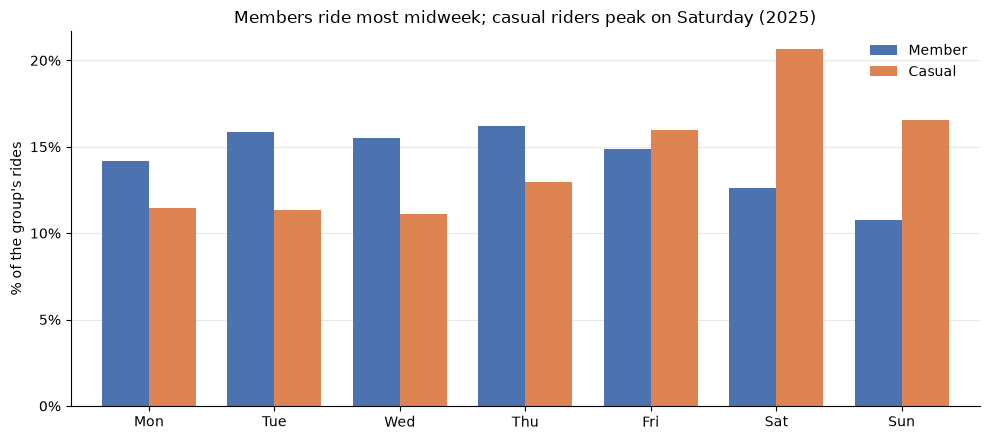

In [9]:
# A bar chart to show the weekly riding pattern by rider group.
ax = weekly[GROUPS].plot(kind="bar", figsize=(10, 4.5), rot=0, width=0.75,
                         color=[COLORS[g] for g in GROUPS])
ax.set_xticklabels([d[:3] for d in day_order])
ax.set_xlabel("")
ax.set_ylabel("% of the group's rides")
ax.yaxis.set_major_locator(mticker.MultipleLocator(5))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title("Members ride most midweek; casual riders peak on Saturday (2025)")
ax.legend(["Member", "Casual"], frameon=False)
tidy(ax)
plt.tight_layout()
plt.show()

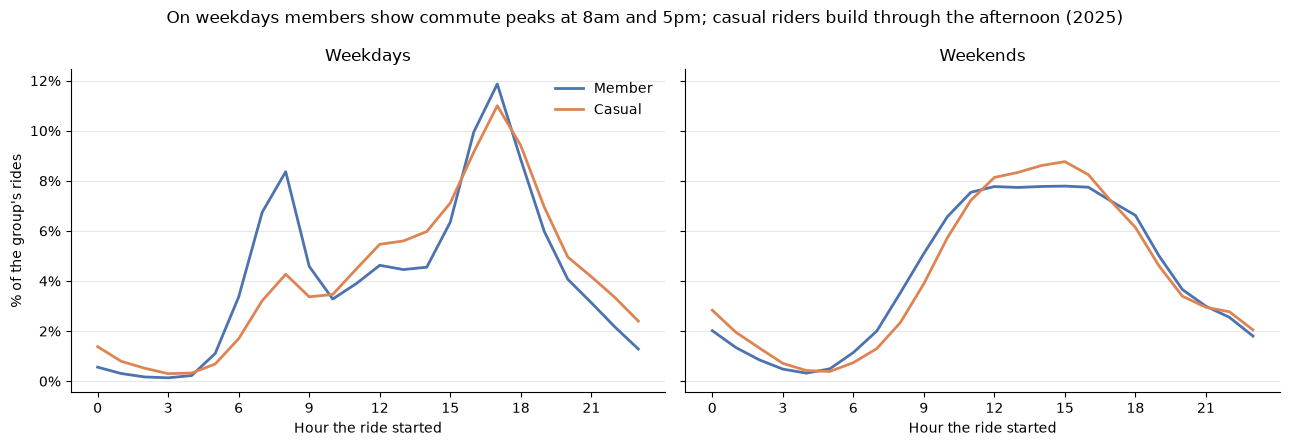

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, weekend, title in [(axes[0], False, "Weekdays"), (axes[1], True, "Weekends")]:
    subset = rides[rides["is_weekend"] == weekend]
    hourly = pd.crosstab(subset["hour"], subset["member_casual"], normalize="columns")[GROUPS] * 100
    for g in GROUPS:
        ax.plot(hourly.index, hourly[g], linewidth=2, color=COLORS[g], label=g.capitalize())
    ax.set_title(title)
    ax.set_xlabel("Hour the ride started")
    ax.set_xticks(range(0, 24, 3))
    tidy(ax)

axes[0].set_ylabel("% of the group's rides")
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
axes[0].legend(frameon=False)
fig.suptitle("On weekdays members show commute peaks at 8am and 5pm; casual riders build through the afternoon (2025)")
plt.tight_layout()
plt.show()

## 4. Ride duration: typical ride patterns are similar, but casual riders have a long tail of leisure rides
Most rides in both groups last about 5 to 20 minutes, but casual riders have a long tail of longer rides.  

In [11]:
# Check how duration of rides are distributed.
pcts = [0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
duration_stats = rides.groupby("member_casual", observed=True)["duration_min"].describe(percentiles=pcts).reindex(GROUPS)

long_ride_share = (rides.assign(over_30=rides["duration_min"] > 30)
                   .groupby("member_casual", observed=True)["over_30"].mean().reindex(GROUPS) * 100)
duration_stats["pct_over_30_min"] = long_ride_share
duration_stats.round(1)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,pct_over_30_min
member_casual,,,,,,,,,,,,
member,3484186.0,12.2,20.5,1.0,5.2,8.7,14.7,23.4,30.9,50.9,1439.9,5.4
casual,1915769.0,19.9,39.6,1.0,6.8,11.9,21.7,39.7,58.8,120.6,1440.0,15.6


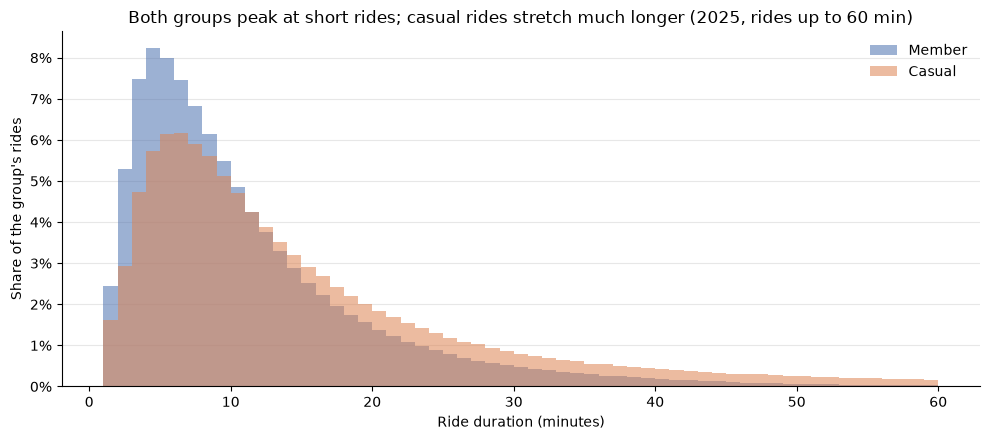

Rides over 60 minutes (not shown): member 0.6%, casual 4.8%


In [12]:
# Plot a ride duration histograms, casual and member groups, in one figure.
bins = np.arange(1, 61, 1)   # 1-minute bins; rides over 60 minutes are summarized below

fig, ax = plt.subplots(figsize=(10, 4.5))
for g in GROUPS:
    ax.hist(rides.loc[rides["member_casual"] == g, "duration_min"], bins=bins, density=True,
            alpha=0.55, color=COLORS[g], label=g.capitalize())

ax.set_xlabel("Ride duration (minutes)")
ax.set_ylabel("Share of the group's rides")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_title("Both groups peak at short rides; casual rides stretch much longer (2025, rides up to 60 min)")
ax.legend(frameon=False)
tidy(ax)
plt.tight_layout()
plt.show()

over_60 = rides.groupby("member_casual", observed=True)["duration_min"].apply(lambda s: (s > 60).mean()).reindex(GROUPS)
print("Rides over 60 minutes (not shown):", ", ".join(f"{g} {v:.1%}" for g, v in over_60.items()))

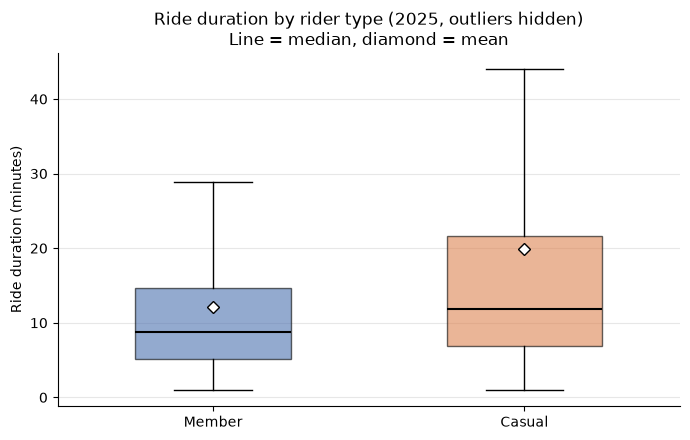

In [13]:
# Box and whisker plot represents wider spread and the long tail seen in the Casual rider group.
fig, ax = plt.subplots(figsize=(7, 4.5))
box = ax.boxplot(
    [rides.loc[rides["member_casual"] == g, "duration_min"] for g in GROUPS],
    tick_labels=["Member", "Casual"],   # use labels= if your matplotlib is older than 3.9
    showfliers=False,                    # outliers hidden; durations run up to 24 hours
    showmeans=True,
    widths=0.5,
    patch_artist=True,
    medianprops={"color": "black", "linewidth": 1.5},
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
)
for patch, g in zip(box["boxes"], GROUPS):
    patch.set_facecolor(COLORS[g])
    patch.set_alpha(0.6)

ax.set_ylabel("Ride duration (minutes)")
ax.set_title("Ride duration by rider type (2025, outliers hidden)\nLine = median, diamond = mean")
tidy(ax)
plt.tight_layout()
plt.show()

## 5. Where: casual riders concentrate along the lakefront and near attractions

Station results use docked rides only (rides with a station name). 

In [14]:
# List top 10 popular stations.
top_n = 10
top_stations = {
    g.capitalize(): (rides.loc[rides["member_casual"] == g, "start_station_name"]
                     .value_counts().head(top_n).index.tolist())
    for g in GROUPS
}
pd.DataFrame(top_stations, index=range(1, top_n + 1))

,Member,Casual
1,Kingsbury St & Kinzie St,DuSable Lake Shore Dr & Monroe St
2,Clinton St & Washington Blvd,Navy Pier
3,Canal St & Madison St,Streeter Dr & Grand Ave
4,Clinton St & Madison St,Michigan Ave & Oak St
5,Clark St & Elm St,DuSable Lake Shore Dr & North Blvd
6,State St & Chicago Ave,Millennium Park
7,Wells St & Elm St,Shedd Aquarium
8,Wells St & Concord Ln,Theater on the Lake
9,Clinton St & Jackson Blvd,Dusable Harbor
10,Wells St & Huron St,Michigan Ave & 8th St


In [15]:
# Station table for the Tableau map: one row per station, month and rider type.
# Starts and ends are both counted as station visits.
visits = pd.concat([
    rides[["start_station_name", "start_lat", "start_lng", "member_casual", "month"]]
        .set_axis(["station_name", "lat", "lng", "member_casual", "month"], axis=1),
    rides[["end_station_name", "end_lat", "end_lng", "member_casual", "month"]]
        .set_axis(["station_name", "lat", "lng", "member_casual", "month"], axis=1),
], ignore_index=True).dropna(subset=["station_name"])

# One fixed location per station (the median of recorded coordinates)
locations = visits.groupby("station_name")[["lat", "lng"]].median()

station_month = (visits
    .groupby(["station_name", "month", "member_casual"], observed=True)
    .size().rename("uses").reset_index()
    .join(locations, on="station_name"))

station_month.to_csv(data_dir / output_folder / "station_usage_by_month.csv", index=False)
print(f"{station_month['station_name'].nunique():,} stations written for Tableau")

1,895 stations written for Tableau


**Station map (Tableau):** each circle is a station, sized by total uses in 2025. Color shows the casual share of uses, from light teal (2%) to dark blue (82%). Colored squares mark notable attractions, museums, viewpoints and Metra commuter rail stations from OpenStreetMap. Hotels and parks are left off the map to keep it readable, because they are spread across almost every area.

The map shows only stations with at least 500 total uses. Stations with very few rides can show an extreme casual share (for example, 100% from two or three rides), which would make quiet outlying stations look like casual hot spots. The same 500-use threshold is used in the proximity analysis below.

The darkest circles sit along the lakefront, close to the attraction and museum markers. The largest light-teal circles are in the Loop and West Loop, near the Metra stations, where members dominate.

- [Open the interactive map on Tableau Public](https://public.tableau.com/app/profile/makiko.tsuda/viz/ChicagoBike-ShareStationMap/BikeStationsandPointsofInterest)

<img src="../output/Stations%20and%20attractions.png" width="70%" alt="Casual riders concentrate at lakefront and attraction stations">

### Do stations near leisure destinations have more casual riders?

The top-station list suggests yes. To check with numbers, each busy station (500+ uses) in the downtown and lakefront area covered by the places download is labeled by whether a notable attraction, museum or viewpoint lies within 300 meters (about a 4-minute walk). Casual share is then compared between the two groups. Parks are left out because almost every neighborhood has one, so they don't distinguish tourist areas.

In [16]:
# A function to calculate the distance from attractions.
def distance_m(lat1, lng1, lat2, lng2):
    """Great-circle distance in meters between arrays of points (haversine formula)."""
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2)
    return 6_371_000 * 2 * np.arcsin(np.sqrt(a))

# Busy stations inside the area covered by the places download
south, west, north, east = 41.83, -87.70, 41.97, -87.58
station_totals = (station_month.pivot_table(index="station_name", columns="member_casual",
                                            values="uses", aggfunc="sum", observed=True)
                  .fillna(0)[GROUPS])
station_totals["uses"] = station_totals.sum(axis=1)
station_totals["casual_pct"] = station_totals["casual"] / station_totals["uses"] * 100
station_totals = station_totals.join(locations)
area = station_totals[(station_totals["uses"] >= 500)
                      & station_totals["lat"].between(south, north)
                      & station_totals["lng"].between(west, east)].copy()

# Notable leisure destinations (major attractions, museums and viewpoints)
leisure = places[places["notable"] & places["category"].isin(["attraction", "museum", "viewpoint"])]

# Distance from every station to every destination; keep the nearest
d = distance_m(area["lat"].values[:, None], area["lng"].values[:, None],
               leisure["lat"].values[None, :], leisure["lng"].values[None, :])
area["nearest_leisure_m"] = d.min(axis=1)
area["near_leisure"] = np.where(area["nearest_leisure_m"] <= 300, "Within 300 m", "Farther away")

# Put it in a table format to compare the ride pattern between stations that are closer to and farther away from notable places.
comparison = area.groupby("near_leisure").agg(
    stations=("uses", "size"),
    total_uses=("uses", "sum"),
    casual_uses=("casual", "sum"),
    median_station_casual_pct=("casual_pct", "median"),
)
comparison["casual_share_pct"] = comparison["casual_uses"] / comparison["total_uses"] * 100
comparison.round(1)

,stations,total_uses,casual_uses,median_station_casual_pct,casual_share_pct
near_leisure,,,,,
Farther away,435,5862184.0,1984563.0,31.9,33.9
Within 300 m,74,1602677.0,662604.0,34.1,41.3


In [17]:
area.sort_values("casual_pct", ascending=False).head(10)[["uses", "casual_pct", "nearest_leisure_m"]].round(0)

,uses,casual_pct,nearest_leisure_m
station_name,,,
Streeter Dr & Grand Ave,59290.0,80.0,252.0
Navy Pier,68958.0,79.0,252.0
Shedd Aquarium,39409.0,79.0,170.0
Field Museum,22033.0,79.0,128.0
DuSable Lake Shore Dr & Monroe St,76468.0,78.0,507.0
McCormick Place,12820.0,72.0,511.0
Adler Planetarium,26085.0,72.0,798.0
Streeter Dr/Grand Ave,7041.0,71.0,283.0
Millennium Park,54242.0,71.0,66.0


## 6. Summary of analysis

**How the analysis was done.** The 12 monthly files were combined into one table of 5.55 million rides, and 2.8% were removed: rides that started in 2024, false starts under 1 minute and rides over 24 hours (see Part 1). Each comparison above uses the same clean table. Rides were compared by count *and* by total riding time, and timing patterns were shown as each group's percentage of its own rides, so that the smaller casual group could be compared fairly with members.

**What it shows.** Members and casual riders use Cyclistic for different purposes:

| | Members | Casual riders |
|---|---|---|
| Share of rides / riding time | 64.5% / 52.7% | 35.5% / 47.3% |
| Average ride | 12.2 min | 19.9 min |
| Rides over 30 minutes | 5.4% | 15.6% |
| Season | Steady; rises about 4× from winter to summer | Strongly seasonal; rises about 14× |
| Busiest days | Tuesday to Thursday | Saturday and Sunday |
| Time of day (weekdays) | Peaks at 8am and 5pm | Builds through the afternoon to 5pm |
| Busiest stations | West Loop and River North, near commuter rail | Lakefront, Navy Pier, museums |

Members ride like **commuters**: short, regular weekday trips that continue through the winter. Casual riders ride like **visitors and leisure riders**: longer rides on summer weekends and afternoons, starting near the lake and major attractions. Busy downtown stations within 300 meters of a major attraction have a higher casual share than those farther away (about 41% versus 34%), and the landmark stations themselves are about 70–80% casual.

**What it means for the marketing goal.** Casual riders already use the bikes heavily, but in a pattern the standard annual membership isn't designed around: they ride mostly in summer and on weekends, and for longer. A conversion campaign is more likely to work if the offer matches that pattern and reaches riders where and when they ride.

## 7. Top three recommendations

**1. Launch a seasonal summer membership.**
- Casual riding grows 14 times from winter to summer, and casual riders account for more riding time than members from June to August (section 2). 
- An annual membership asks a summer rider to pay for months they won't ride. A May-to-September membership, priced between day passes and the annual plan, matches how casual riders actually ride. 
- Start promoting it in April, when casual riding begins to rise, and offer summer members a credit toward the annual plan in September to convert them fully.

**2. Build membership benefits around longer leisure rides, and promote them on weekends.**
- Casual riders are about three times as likely as members to ride for more than 30 minutes (section 4), and they ride most on Saturday and Sunday afternoons (section 3). Membership offers that reward longer rides, such as more included minutes per ride, speak directly to that pattern. 
- Show these offers in the app and at docks on weekends, when casual riders take nearly half of all rides, using messages that compare a summer of weekend rides on day passes with the cost of membership.

**3. Target the lakefront and attraction stations with on-site promotions and partner discounts.**
- The busiest stations among casual riders are at Navy Pier, Millennium Park, Shedd Aquarium, the Field Museum and along the lakefront, where about 70–80% of riders are casual (section 5). 
- Place membership promotions at these docks and in the app. Partner with nearby attractions, museums, restaurants and cafés to give members discounts, which turns membership into a benefit that casual riders value on the trips they're already taking.

## 8. Limitations and next steps

**Limitations of this analysis**

- **No rider IDs.** The data can't show how many individual casual riders there are, how often each one rides, or whether they are local residents or visitors. That matters for recommendation 1: a seasonal membership appeals most to local summer riders, not one-time tourists.
- **One year of data.** Patterns may vary from year to year. The temperature table in section 2 compares 2025 with the 2020–2025 average to show whether 2025 was a typical year.
- **Station results cover docked rides only.** About 1 in 5 rides (mostly e-bikes parked away from docks) has no station name and is left out of the station rankings and map.
- **Points of interest** come from OpenStreetMap, which is maintained by volunteers, and cover downtown and the lakefront only.
- **Correlation, not cause.** Temperature and casual riding move together across 12 months, but other seasonal factors, such as tourism, school holidays and events, also peak in summer.
- **No pricing or revenue data,** so the recommendations can't yet be tested for profitability.

**Next steps**

- Test the summer membership with a small group of casual riders before a full launch, and measure conversions to the annual plan.
- Ask the finance team for pricing and revenue by rider type to estimate the value of each converted rider.
- Answer the team's other questions with digital media in mind (why casual riders would buy a membership, and how digital media can influence them). Ideas to explore in the app:
  - Show the estimated travel time by car for the same trip, which highlights the value of the bike for regular trips.
  - Show each rider's environmental impact (for example, car miles avoided) and the total for all Cyclistic riders.
  - Test a reduced weekday midday rate to attract casual riders outside the weekend peak.